In [29]:
# Imports and Setup

from glass_dynamics.core.logger import logger

from glass_dynamics.data.processor import filter_and_fit_dataset
from glass_dynamics.data.composition import gen_atomic_df
from glass_dynamics.data.splitting import split_by_cassar_indices, split_by_random_seed

from glass_dynamics.features.generator import generate_all_features, generate_cassar_35_features
from glass_dynamics.features.correlation import select_features_from_clusters
from glass_dynamics.features.vif import calculate_vif, calculate_ridge_vif, iterative_vif_selection, fast_iterative_vif_selection

from glass_dynamics.analysis.performance import compute_alpha_performance_metrics
from glass_dynamics.analysis.traces import compute_weight_traces
from glass_dynamics.analysis.feature_importance_old import extract_importance
from glass_dynamics.analysis.evolution import extract_top_features_evolution
from glass_dynamics.analysis.extrapolation import generate_extrapolation_metrics
from glass_dynamics.analysis.myega_bootstrap import generate_bootstrap_predictions
from glass_dynamics.analysis.residuals_analysis import compute_global_viscosity_residuals
from glass_dynamics.analysis.ridge_viscosity_grid import compute_ridge_viscosity_alpha_grid

# from glass_dynamics.analysis.sample_weights import compute_myega_fit_weights
from glass_dynamics.analysis.quality_filter import (
    evaluate_experimental_fit_quality,
    filter_noisy_liquids
)

from glass_dynamics.visualization.features_exploration_plots import plot_pearson_correlation, generate_feature_metadata_table
from glass_dynamics.visualization.performance_plots import plot_target_performance
from glass_dynamics.visualization.traces_plots import plot_normalized_traces
from glass_dynamics.visualization.importance_plots import plot_sorted_feature_importance
from glass_dynamics.visualization.evolution_plots import plot_top_features_evolution
from glass_dynamics.visualization.density_plots import plot_viscosity_density_correlation
from glass_dynamics.visualization.distance_plots import plot_rmse_vs_distance_square
from glass_dynamics.visualization.viscosity_grids import plot_viscosity_grids_bootstrap
from glass_dynamics.visualization.residuals_plots import plot_viscosity_compound_residuals
from glass_dynamics.visualization.ridge_viscosity_plots import plot_ridge_viscosity_alpha_grid
from glass_dynamics.visualization.viscosity_grids_plots import plot_viscosity_grids


from glass_dynamics.models.ridge import CustomRidgeRegression

from glass_dynamics.evaluation.model_evaluation import evaluate_final_model

from glass_dynamics.utils.naming import generate_glass_names

import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from pathlib import Path
import pickle


analysis_name = "weighted_ridge"

data_path = Path(f"../../data/cassar_split/base_analysis")
plots_path = Path(f"../../plots/ridge/{analysis_name}")
model_path = Path(f"../../models/ridge/{analysis_name}")
plots_path.mkdir(parents=True, exist_ok=True)
data_path.mkdir(parents=True, exist_ok=True)
model_path.mkdir(parents=True, exist_ok=True)


In [2]:
# Data Loading
logger.info("Loading raw datasets...")

raw_data = pd.read_csv('../../data/viscosity_raw_data.csv', index_col=0)
chemical_props_T = pd.read_csv("../../data/chemical_properties.csv", index_col=0).T
chemical_props = pd.read_csv("../../data/chemical_properties.csv", index_col=0)
# raw_data


[INFO] 2026-10-15 14:04:30 - Loading raw datasets...


In [3]:
# MYEGA Fit and Filter
clean_glasses_df, rejected_glasses_df = filter_and_fit_dataset(raw_data, min_r2_threshold=0.95)
y_targets = clean_glasses_df[['ID', 'Tg_fitted', 'm_fitted', 'log_eta_inf_fitted']].set_index('ID')
oxides_df = clean_glasses_df.drop(columns=['Tg_fitted', 'm_fitted', 'log_eta_inf_fitted', 'myega_r2', 'myega_rmse']).set_index('ID')
# oxides_df


[INFO] 2026-10-15 14:04:30 - Starting data processing and MYEGA fitting on 847 unique glasses...
[INFO] 2026-10-15 14:04:37 - Processing complete. Accepted glasses: 847. Rejected glasses: 0.


In [4]:
# Convert Oxides to Elements
atomic_df = gen_atomic_df(oxides_df, chemical_props_T)
# atomic_df


[INFO] 2026-10-15 14:04:37 - Converting compound fractions to elemental atomic fractions using chemparse...
[INFO] 2026-10-15 14:04:37 - Successfully converted. Output shape: (847, 59)


In [5]:
# # Generate cassar viscnet features
# X_cassar_features = generate_cassar_35_features(atomic_df, chemical_props)
# X_cassar_features

In [6]:
# This generates 560 features
X_all_features = generate_all_features(atomic_df, chemical_props)
# X_all_features


[INFO] 2026-10-15 14:04:37 - Generating all W and A features from 56 chemical properties...
[INFO] 2026-10-15 14:05:12 - Feature generation complete. Total features created: 560


In [7]:
# Data splitting
X_train, X_test, y_train, y_test = split_by_cassar_indices(X_all_features, y_targets, "../../data/cassar_split/test_ids.parquet")
# X_test

[INFO] 2026-10-15 14:05:12 - Splitting dataset using predefined indices from ../../data/cassar_split/test_ids.parquet...
[INFO] 2026-10-15 14:05:12 - Split complete. Train size: 762, Test size: 85


In [8]:
# Standardize features and output
X_scaler = StandardScaler().set_output(transform="pandas")
X_train_scaled = X_scaler.fit_transform(X_train)
X_test_scaled = X_scaler.transform(X_test)

y_scaler = StandardScaler().set_output(transform="pandas")
y_train_scaled = y_scaler.fit_transform(y_train)
y_test_scaled = y_scaler.transform(y_test)

# y_test_scaled

In [9]:
# Saving data
# X_train_final_standard = X_train_scaled[features_with_std]
# X_test_final_standard = X_test_scaled[features_with_std]
X_train_final_standard = X_train_scaled
X_test_final_standard = X_test_scaled

X_train_final_standard.to_parquet(data_path / 'X_train.parquet')
X_test_final_standard.to_parquet(data_path / 'X_test.parquet')

y_train.to_parquet('../../data/cassar_split/y_train.parquet')
y_test.to_parquet('../../data/cassar_split/y_test.parquet')

In [11]:
# # Model performance analysis as a function of alpha
# alphas_spectrum = np.logspace(-5, 3, 100)

# performance_results = compute_alpha_performance_metrics(
#     X_train_final_standard, 
#     y_train_scaled, 
#     X_test_final_standard, 
#     y_test_scaled, 
#     alphas_spectrum
# )

# performance_plots_path = plots_path / "performance_plots"
# performance_plots_path.mkdir(parents=True, exist_ok=True)

# for target in performance_results.keys():
#     fig = plot_target_performance(
#         performance_results[target],
#         target_name=target,
#         ref_alpha=0.01
#     )
#     fig.savefig(performance_plots_path / f"{target}.pdf", bbox_inches='tight')

[INFO] 2026-10-15 14:05:12 - Computing train and test global viscosity metrics across 100 alpha values.
[INFO] 2026-10-15 14:05:31 - Rendering Ridge global viscosity alpha grid plots.


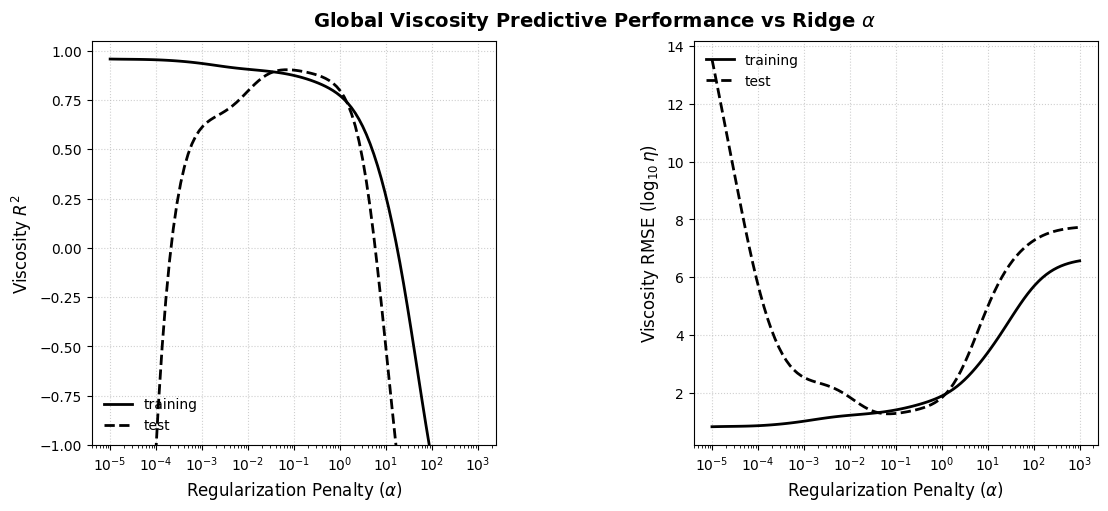

In [ ]:
alphas_spectrum = np.logspace(-5, 3, 100)

base_ridge = CustomRidgeRegression(fit_intercept=True)

ridge_metrics = compute_ridge_viscosity_alpha_grid(
    base_model=base_ridge,
    alpha_array=alphas_spectrum,
    X_train=X_train_final_standard,
    y_train=y_train_scaled,
    X_test=X_test_final_standard,
    y_test=y_test_scaled,
    viscosity_df=raw_data,
    y_scaler=y_scaler
)

viscosity_plots_path = plots_path / "global_viscosity_grids"
viscosity_plots_path.mkdir(parents=True, exist_ok=True)

fig_ridge = plot_ridge_viscosity_alpha_grid(ridge_metrics)
fig_ridge.savefig(viscosity_plots_path / "Ridge_Global_Viscosity_vs_Alpha.pdf", bbox_inches='tight')



In [13]:
# # Features weights analysis in relation to alpha
# traces_alphas_spectrum = np.logspace(-8, 3, 40)

# robust_traces = compute_weight_traces(
#     X=X_train_final_standard,
#     y=y_train_scaled,
#     alphas=traces_alphas_spectrum,
#     n_splits=20,
#     test_size=0.5
# )

# target_names = list(robust_traces.keys())

# traces_plots_path = plots_path / "traces_plots"
# traces_plots_path.mkdir(parents=True, exist_ok=True)

# for target in target_names:
#     mean_df = robust_traces[target]["mean_weights"]
#     std_df = robust_traces[target]["std_weights"]

#     fig = plot_normalized_traces(
#         mean_weights=mean_df,
#         std_weights=std_df,
#         target_name=target
#     )
#     fig.savefig(traces_plots_path / f"{target}.pdf", bbox_inches='tight')

[INFO] 2026-10-15 14:05:32 - Extracting raw feature importance at alpha=0.1 over 100 splits.
[INFO] 2026-10-15 14:05:45 - Rendering sorted raw feature importance S-curves for 3 targets.


,feature,original_index,weight,std,abs_weight
0,W_Sum_lattice_constant,174,0.096501,0.012980,0.096501
1,W_Sum_vdw_radius_uff,284,-0.090711,0.016903,0.090711
2,A_Min_ElectronAffinity,356,-0.089579,0.015732,0.089579
3,A_Max_FusionEnthalpy,375,-0.081847,0.024274,0.081847
4,W_Std_num_oxistates,343,-0.077492,0.017681,0.077492
5,W_Min_ElectronAffinity,351,-0.077226,0.026441,0.077226
6,W_Sum_GSbandgap,384,0.076510,0.010876,0.076510
7,W_Max_FusionEnthalpy,370,-0.066397,0.025131,0.066397
8,W_Sum_NUnfilled,454,-0.065780,0.012660,0.065780
9,W_Sum_NpUnfilled,514,-0.064225,0.011513,0.064225


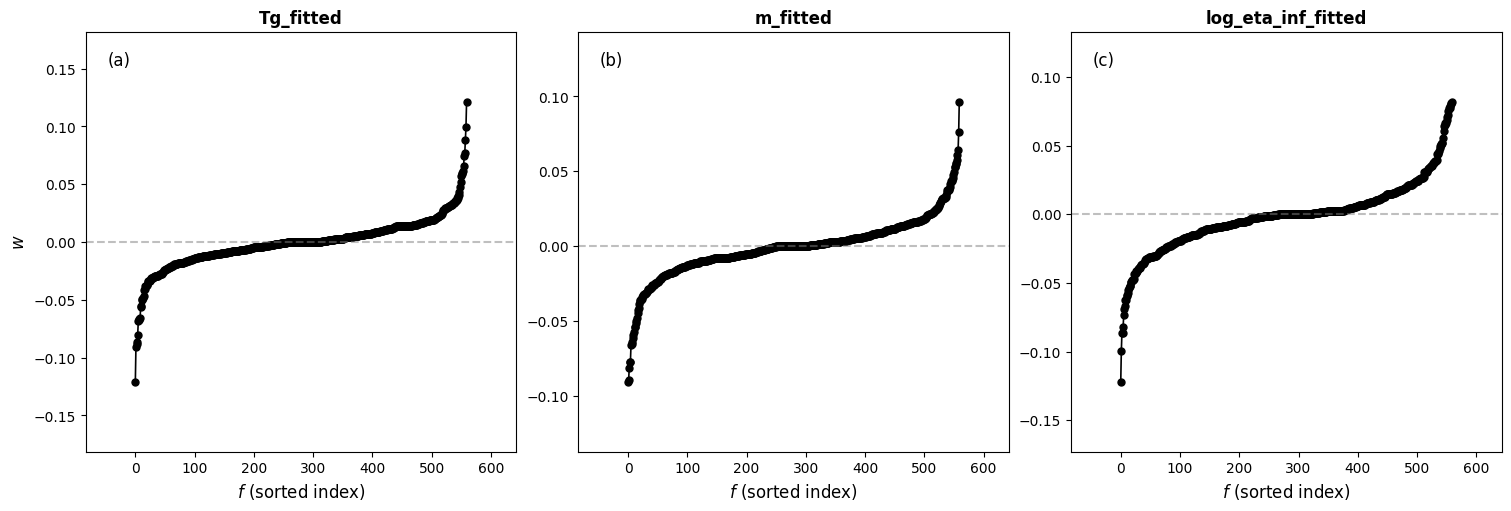

In [ ]:
# Feature weights plots (ordered)
importance_data = extract_importance(
    X=X_train_final_standard,
    y=y_train_scaled,
    alpha=0.1,
    n_splits=100,
    sort_by='magnitude'
)

fig_importance = plot_sorted_feature_importance(importance_data, top_n=0)
fig_importance.savefig(plots_path / 'features_importance_ridge.pdf', bbox_inches='tight')


importance_data['m_fitted'].head(20)
# print("\nTop 10 features per Tg_fitted:")
# print(importance_data['Tg_fitted'].head(10)[['original_index', 'feature', 'weight', 'abs_weight']])

In [15]:
importance_data['log_eta_inf_fitted'].head(20)

,feature,original_index,weight,std,abs_weight
0,A_Min_ElectronAffinity,356,-0.121912,0.035718,0.121912
1,W_Min_melting_point,191,-0.099393,0.037648,0.099393
2,A_Sum_GSmagmom,429,-0.086534,0.024412,0.086534
3,A_Max_GSmagmom,425,-0.086533,0.024412,0.086533
4,W_Sum_vdw_radius_uff,284,-0.082141,0.018219,0.082141
5,W_Mean_GSmagmom,422,0.082044,0.021220,0.082044
6,W_Sum_FusionEnthalpy,374,0.080854,0.018884,0.080854
7,W_Min_c6_gb,61,0.080089,0.045177,0.080089
8,A_Max_num_oxistates,345,0.079198,0.030039,0.079198
9,A_Sum_NpUnfilled,519,0.077380,0.020760,0.077380


In [ ]:
# Training model

# Instantiate the model with alpha = 0.01
weighted_ridge_model = CustomRidgeRegression(alpha=0.1, fit_intercept=True)

# Fit the model on the training data
weighted_ridge_model.fit(X_train_scaled, y_train_scaled)

pickle.dump(weighted_ridge_model, open(model_path / "weighted_ridge_model.pkl", 'wb'))

logger.info("Model successfully trained and saved!")

[INFO] 2026-10-15 14:09:34 - Model successfully trained and saved!


In [55]:
# Evaluating model

target_columns = ['Tg', 'm','log_eta_inf']

# 1. Calcola la qualità del fit MYEGA su Train e Test
train_quality = evaluate_experimental_fit_quality(raw_data, y_train_scaled, y_scaler=y_scaler)
test_quality = evaluate_experimental_fit_quality(raw_data, y_test_scaled, y_scaler=y_scaler)

print("=== TOP 15 LIQUIDI PIÙ RUMOROSI NEL TRAINING SET ===")
display(train_quality.head(15))

print("=== TOP 10 LIQUIDI PIÙ RUMOROSI NEL TEST SET ===")
display(test_quality.head(10))

# -------------------------------------------------------------------------
# ESPERIMENTO A: Pulizia del solo Training Set (Test Set intatto)
# Proviamo a rimuovere i vetri di training con RMSE del fit MYEGA > 0.4
# (oppure usa drop_worst_pct=5.0 per togliere il peggior 5%)
# -------------------------------------------------------------------------
X_train_clean, y_train_clean, dropped_train = filter_noisy_liquids(
    X=X_train_scaled,
    y=y_train_scaled,
    quality_df=train_quality,
    max_rmse=0.2  # <-- Soglia fisica in unità di log10(eta); prova anche 0.3 o 0.5
)

print(f"\n[ESPERIMENTO A] Liquidi rimossi dal Train: {len(dropped_train)}")
print("ID rimossi:", dropped_train.index.tolist())

results_exp_A = evaluate_final_model(
    model=CustomRidgeRegression(alpha=0.05),
    X_train=X_train_clean,
    y_train=y_train_clean,
    X_test=X_test_scaled,      # Test set originale intatto
    y_test=y_test_scaled,
    viscosity_df=raw_data,
    y_scaler=y_scaler
)

[INFO] 2026-10-15 16:34:04 - Evaluated experimental MYEGA fit quality for 762 liquids. Median RMSE: 0.1141, Max RMSE: 0.5514
[INFO] 2026-10-15 16:34:04 - Evaluated experimental MYEGA fit quality for 85 liquids. Median RMSE: 0.1127, Max RMSE: 0.4570
=== TOP 15 LIQUIDI PIÙ RUMOROSI NEL TRAINING SET ===


,n_points,myega_mse,myega_rmse,myega_mae,myega_max_err
ID,,,,,
745,11,0.303993,0.551355,0.455864,0.863151
190,33,0.265686,0.515448,0.445316,0.884367
197,17,0.250386,0.500386,0.444620,0.876262
438,13,0.212554,0.461036,0.397421,0.744113
387,28,0.211996,0.460431,0.389038,0.891856
448,22,0.211516,0.459909,0.379898,0.888907
744,12,0.207597,0.455628,0.356372,0.869442
697,25,0.207226,0.455221,0.401247,0.901009
380,35,0.206666,0.454605,0.360125,1.006320


=== TOP 10 LIQUIDI PIÙ RUMOROSI NEL TEST SET ===


,n_points,myega_mse,myega_rmse,myega_mae,myega_max_err
ID,,,,,
155,42,0.208868,0.457021,0.412290,0.808686
201,50,0.195566,0.442228,0.341183,1.094181
123,50,0.126679,0.355921,0.293558,0.873327
141,29,0.123713,0.351729,0.260322,0.961662
14,33,0.116333,0.341077,0.210289,1.053539
846,11,0.114318,0.338110,0.258836,0.778872
26,19,0.112482,0.335383,0.239639,0.855857
326,23,0.101275,0.318237,0.225977,0.667750
273,13,0.099237,0.315019,0.276403,0.555209


[INFO] 2026-10-15 16:34:04 - Filtered noisy liquids [max_rmse=0.2000]: kept 564/762 (198 noisy liquids removed).

[ESPERIMENTO A] Liquidi rimossi dal Train: 198
ID rimossi: [745, 190, 197, 438, 387, 448, 744, 697, 380, 154, 801, 538, 373, 743, 791, 252, 124, 243, 113, 324, 626, 681, 359, 605, 680, 146, 75, 793, 133, 184, 396, 63, 414, 368, 379, 135, 596, 72, 235, 327, 149, 399, 49, 2, 370, 172, 0, 553, 74, 24, 253, 447, 77, 195, 369, 42, 127, 31, 323, 385, 214, 198, 161, 335, 125, 183, 443, 30, 723, 439, 237, 150, 398, 576, 329, 303, 415, 386, 330, 367, 266, 321, 176, 540, 239, 148, 792, 238, 493, 242, 444, 574, 254, 325, 299, 416, 223, 84, 107, 101, 397, 298, 7, 121, 795, 270, 539, 159, 627, 240, 271, 634, 217, 219, 658, 234, 43, 116, 789, 274, 15, 209, 395, 174, 455, 251, 272, 649, 152, 419, 62, 202, 762, 614, 515, 437, 196, 28, 446, 12, 400, 175, 102, 216, 440, 106, 206, 657, 441, 21, 120, 752, 794, 45, 10, 471, 185, 151, 3, 541, 843, 418, 153, 64, 203, 292, 44, 241, 59, 47, 86, 211

In [58]:
# -------------------------------------------------------------------------
# ESPERIMENTO B: Curatela Globale (Rimozione curve corrotte da Train e Test)
# Applichiamo esattamente la stessa soglia oggettiva di qualità sperimentale
# -------------------------------------------------------------------------
X_test_clean, y_test_clean, dropped_test = filter_noisy_liquids(
    X=X_test_scaled,
    y=y_test_scaled,
    quality_df=test_quality,
    max_rmse=0.15
)

print(f"\n[ESPERIMENTO B] Liquidi corrotti rimossi dal Test: {len(dropped_test)}")
print("ID Test rimossi:", dropped_test.index.tolist())

results_exp_B = evaluate_final_model(
    model=CustomRidgeRegression(alpha=0.025),
    X_train=X_train_clean,
    y_train=y_train_clean,
    X_test=X_test_clean,       # Test set privo di curve biforcate
    y_test=y_test_clean,
    viscosity_df=raw_data,
    y_scaler=y_scaler
)

[INFO] 2026-10-15 16:34:41 - Filtered noisy liquids [max_rmse=0.1500]: kept 52/85 (33 noisy liquids removed).

[ESPERIMENTO B] Liquidi corrotti rimossi dal Test: 33
ID Test rimossi: [155, 201, 123, 141, 14, 846, 26, 326, 273, 390, 806, 51, 68, 366, 268, 544, 93, 132, 663, 265, 528, 233, 445, 17, 405, 91, 844, 835, 296, 293, 181, 18, 449]
[INFO] 2026-10-15 16:34:41 - Training (unweighted) and Evaluating CustomRidgeRegression on the unseen Test Set (52 glasses)...

      TEST SET PERFORMANCE (SCALED PARAMETERS)
Target: Tg
  Pearson : 0.958
  R^2     : 0.916
  RMSE    : 0.237
  MAE     : 0.179
  MedAE   : 0.146
--------------------------------------------------
Target: m
  Pearson : 0.897
  R^2     : 0.803
  RMSE    : 0.368
  MAE     : 0.278
  MedAE   : 0.203
--------------------------------------------------
Target: log_inf
  Pearson : 0.682
  R^2     : 0.456
  RMSE    : 0.612
  MAE     : 0.477
  MedAE   : 0.368
--------------------------------------------------
[INFO] 2026-10-15 16:34:4

[INFO] 2026-10-15 16:34:47 - Rendering 2D density correlation plot with residual inset.


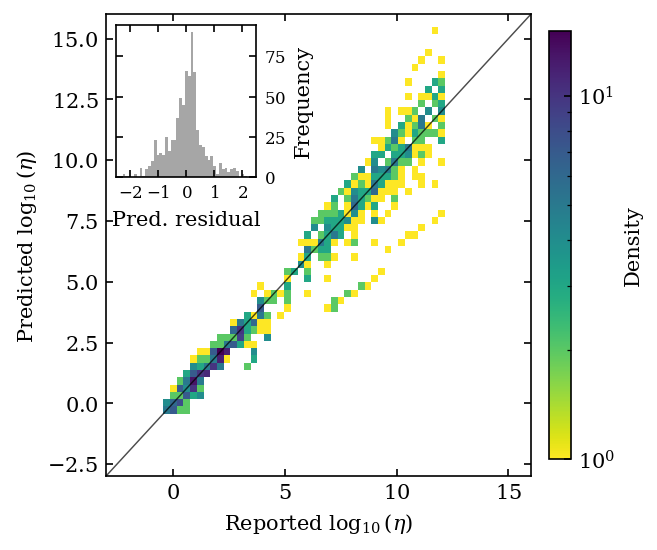

In [59]:
# Cassar density plot

y_true_visc = results_exp_B["viscosity_arrays"]["true_experimental"]
y_pred_visc = results_exp_B["viscosity_arrays"]["predicted_myega"]

fig_density = plot_viscosity_density_correlation(
    y_true=y_true_visc, 
    y_pred=y_pred_visc
)

fig_density.savefig(plots_path / '2D_density_histogram.pdf', bbox_inches='tight')
fig_density.savefig(plots_path / '2D_density_histogram.png', bbox_inches='tight')

[INFO] 2026-10-15 16:35:04 - Extracting distance and RMSE metrics into a DataFrame.


,ID,Name,Distance,RMSE
0,846,25Li₂O.25Na₂O.50P₂O₅,1.321678,5.080817
1,709,1Al₂O₃.50P₂O₅.18SrO.31ZnO,2.010101,4.992816
2,220,74B₂O₃.16BaO.10La₂O₃,1.110106,3.422425
3,233,7Al₂O₃.11BeO.3K₂O.4Na₂O.76SiO₂,1.227778,3.232396
4,265,15Al₂O₃.65B₂O₃.20CaO,0.151111,3.152632
5,273,8Al₂O₃.60B₂O₃.32CaO,0.143369,2.563277
6,201,50Na₂O.50P₂O₅,0.100251,2.386734
7,659,54B₂O₃.21Na₂O.25SiO₂,0.428105,2.209764
8,293,20BeO.60GeO₂.20Na₂O,0.410256,1.978165
9,544,1Al₂O₃.21B₂O₃.4Na₂O.74SiO₂,0.369825,1.963054


[INFO] 2026-10-15 16:35:04 - Rendering square scatter plot for Extrapolation Distance vs RMSE.


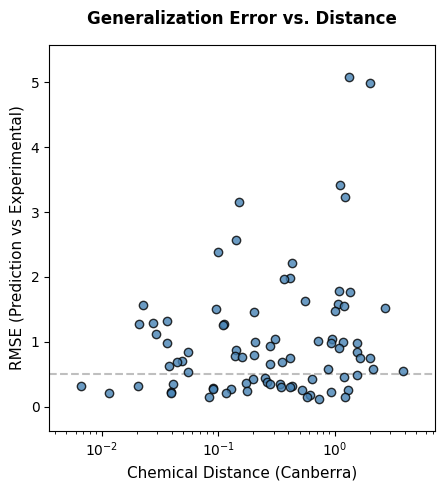

In [60]:
# Test glasses vs performance analysis

# Get glass names
compounds = raw_data.columns[:-3].tolist()
glass_names_dict = generate_glass_names(raw_data, compounds)

# Get model prediction
y_pred_scaled  = weighted_ridge_model.predict(X_test_final_standard)
y_pred_physical = y_scaler.inverse_transform(y_pred_scaled)

target_columns = ['Tg', 'm','log_inf']

# Prediction dataframe
predictions_df = pd.DataFrame(
    y_pred_physical,
    columns=target_columns,
    index=y_test.index
)

# Generating distance data
metrics_df = generate_extrapolation_metrics(
    compounds=compounds,
    viscosity_df=raw_data,
    predictions_df=predictions_df, 
    names_dict=glass_names_dict
)
display(metrics_df.head(10))

# Generating distance plot
fig_distance = plot_rmse_vs_distance_square(metrics_df)
fig_distance.savefig(plots_path / 'distance_plot.pdf', bbox_inches='tight')

In [20]:
test_ids = X_test_final_standard.index
oxide_columns = [col for col in raw_data.columns if col not in ['T', 'log_visc', 'ID']]

composition_test_df = raw_data[raw_data['ID'].isin(test_ids)].copy()
composition_test_df = composition_test_df.drop_duplicates(subset=['ID'])
composition_test_df = composition_test_df.set_index('ID')
composition_test_df = composition_test_df[oxide_columns]
composition_test_df = composition_test_df.fillna(0)

composition_test_df

,Al2O3,As2O3,B2O3,BaO,BeO,Bi2O3,CaO,CdO,CoO,Cs2O,...,SiO2,SrO,Ta2O5,TeO2,TiO2,Tl2O,WO3,Y2O3,ZnO,ZrO2
ID,,,,,,,,,,,,,,,,,,,,,
5,0.00,0.0,0.00,0.0,0.0,0.0,0.00,0.0,0.0,0.0,...,0.77,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0
8,0.00,0.0,0.00,0.0,0.0,0.0,0.00,0.0,0.0,0.0,...,0.83,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0
14,0.00,0.0,0.00,0.0,0.0,0.0,0.00,0.0,0.0,0.0,...,0.85,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0
17,0.00,0.0,0.00,0.0,0.0,0.0,0.00,0.0,0.0,0.0,...,0.60,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0
18,0.00,0.0,0.00,0.0,0.0,0.0,0.00,0.0,0.0,0.0,...,0.50,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
815,0.00,0.0,0.00,0.0,0.0,0.0,0.06,0.0,0.0,0.0,...,0.73,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0
819,0.00,0.0,0.00,0.0,0.0,0.0,0.06,0.0,0.0,0.0,...,0.71,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.02,0.0
835,0.01,0.0,0.24,0.0,0.0,0.0,0.03,0.0,0.0,0.0,...,0.68,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0


[INFO] 2026-10-15 14:05:49 - Computing global viscosity residuals across chemical compounds.
[INFO] 2026-10-15 14:05:49 - Rendering global viscosity compound residual plot.


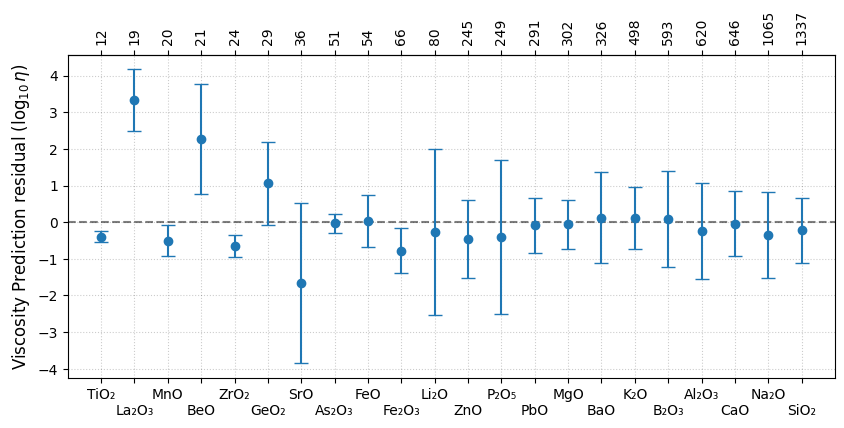

In [21]:
# composition_test_df è il DataFrame con le moli (Na2O, SiO2...) per i vetri nel Test Set
viscosity_residuals_df = compute_global_viscosity_residuals(
    viscosity_df=raw_data,               # Il dataset sperimentale (con le colonne ID, T, log_visc)
    predictions_df=predictions_df,       # I tre parametri predetti
    composition_df=composition_test_df   # Le frazioni molari degli ossidi
)

residuals_plots_path = plots_path / "residuals_analysis"
residuals_plots_path.mkdir(parents=True, exist_ok=True)

fig_visc_res = plot_viscosity_compound_residuals(viscosity_residuals_df)
fig_visc_res.savefig(residuals_plots_path / "Global_Viscosity_Error_Compound.pdf", bbox_inches='tight')

In [22]:
# y_pred_scaled = ridge_model.predict(X_test_scaled)
# y_pred_physical = y_scaler.inverse_transform(y_pred_scaled)
# predictions_df = pd.DataFrame(
#     y_pred_physical, 
#     columns=['Tg', 'm', 'log_inf'], 
#     index=X_test_scaled.index
# )

# viscosity_plots_path = plots_path / "test_viscosity_plots_deterministic"
# viscosity_plots_path.mkdir(parents=True, exist_ok=True)

# plot_viscosity_grids(
#     viscosity_df=raw_data,        # Il tuo dataset originale con 'ID', 'T', 'log_visc'
#     predictions_df=predictions_df,   # Il dataframe appena calcolato
#     names_dict=glass_names_dict,     # Il tuo dizionario dei nomi
#     save_dir=viscosity_plots_path,
#     num_rows=5,
#     num_cols=4
# )


[INFO] 2026-10-15 14:05:50 - Training ensemble of 100 bootstrap models...
[INFO] 2026-10-15 14:06:04 - Rendering bootstrap prediction grids for 85 glasses.


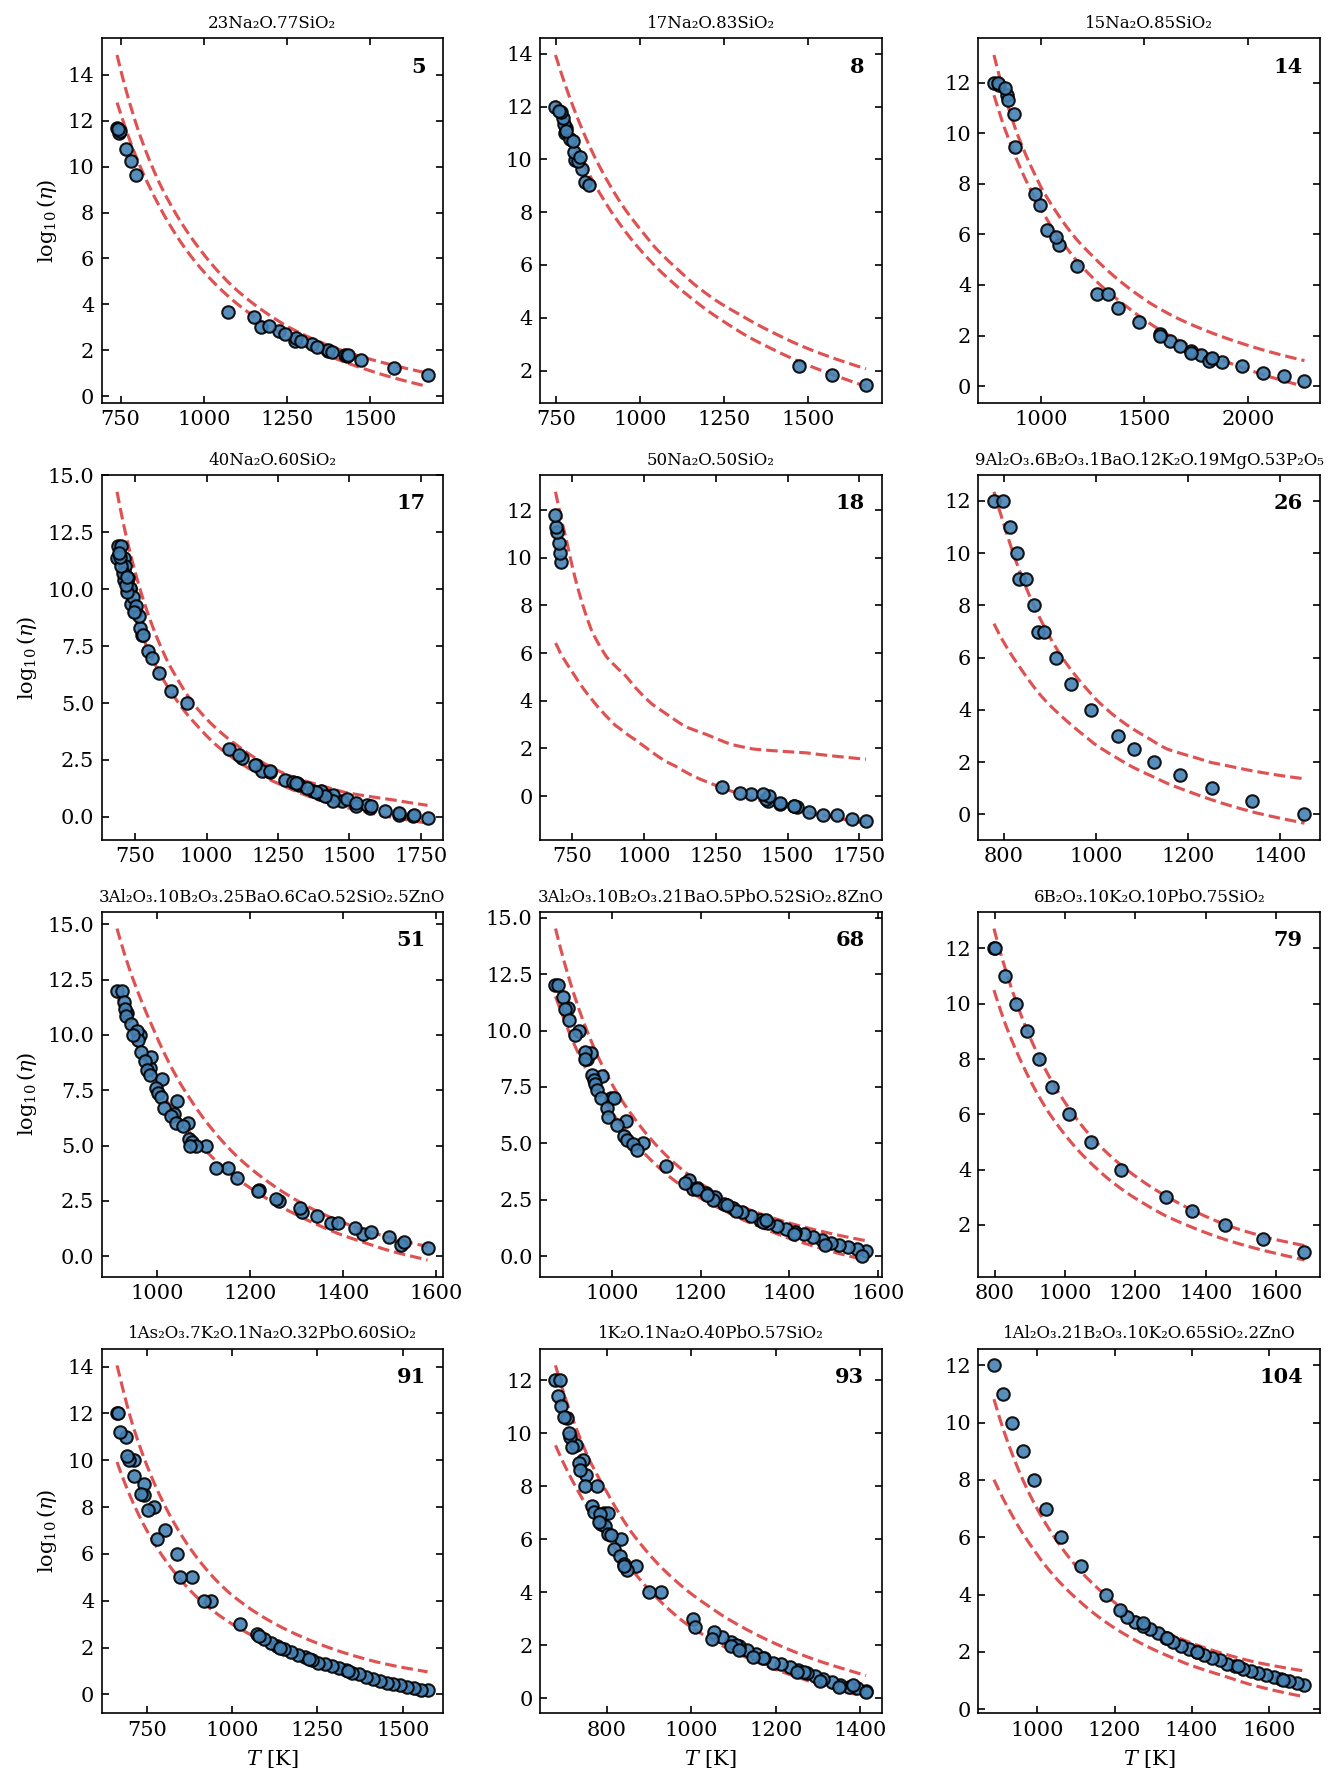

In [23]:
# Plotting test liquids viscosities with uncertainty bars

base_ridge = CustomRidgeRegression(alpha=0.01, fit_intercept=True)

predictions_df, distributions_dict = generate_bootstrap_predictions(
    base_model=base_ridge,
    X_train=X_train_final_standard,
    y_train=y_train_scaled,
    X_test=X_test_final_standard,
    y_scaler=y_scaler,
    n_estimators=100
)

viscosity_plots_path = plots_path / "test_viscosity_plots_tesi"
viscosity_plots_path.mkdir(parents=True, exist_ok=True)

plot_viscosity_grids_bootstrap(
    viscosity_df=raw_data,
    distributions_dict=distributions_dict,
    names_dict=glass_names_dict,
    save_dir=viscosity_plots_path,
    confidence=95.0,
    num_rows=4,
    num_cols=3
)